# Detección de similitud entre programas Python
## Cuaderno 2. Representación, entrenamiento y evaluación

**Conjunto:** PoolC, muestra preparada de 3 000 pares.  
**Objetivo:** predecir la etiqueta de similitud asignada a un par de programas Python.  
**Método:** clasificación supervisada con características léxicas y estructurales.  
**Entorno:** Python y scikit-learn, sin GPU y sin ejecutar el código recibido.

Este notebook reproduce las decisiones observadas en el experimento de Datalore. Se comparan un criterio léxico simple y un bosque aleatorio. Todas las decisiones sobre selección de umbral se toman en validación; la prueba permanece reservada para la estimación final. Una predicción positiva no demuestra plagio.

## 1. Bibliotecas y configuración de reproducibilidad

La semilla fija facilita reproducir el entrenamiento y la comparación. `tokenize` representa los componentes léxicos del código, mientras que `ast` extrae relaciones sintácticas sin ejecutarlo. Los resultados pueden variar ligeramente con versiones diferentes de bibliotecas, por lo que el ambiente debe consignarse al reproducir la práctica.

In [1]:
import ast
import hashlib
import io
import re
import tokenize
import warnings
import zipfile
from collections import Counter
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
)

SEED = 42
print("Versiones:", "numpy", np.__version__, "pandas", pd.__version__)

Versiones: numpy 2.3.5 pandas 2.2.3


## 2. Carga y verificación de las particiones fijadas

Se utiliza el ZIP generado por la preparación de datos. No se ejecuta una nueva partición aleatoria, porque ello podría reintroducir fragmentos repetidos entre entrenamiento y prueba. Se verifican las columnas indispensables, la presencia de las dos clases y la independencia por huellas y grupos.

El conjunto original dispone de once columnas tras la curaduría. De ellas, únicamente los dos fragmentos de código participan en el cálculo de características; los grupos y los identificadores no se utilizan para entrenar.

In [2]:
possible = [Path('/data/notebook_files/poolc_prepared.zip'), Path('poolc_prepared.zip'), Path('/mnt/data/poolc_prepared.zip')]
zip_path = next((p for p in possible if p.exists()), None)
if zip_path is None:
    raise FileNotFoundError('Cargue poolc_prepared.zip en los archivos del notebook de Datalore.')
with zipfile.ZipFile(zip_path) as z:
    data = {s: pd.read_csv(io.BytesIO(z.read(f'poolc_prepared/{s}.csv')))
            for s in ('train','validation','test')}
for split, df in data.items():
    assert {'code1','code2','similar','code1_group','code2_group','hash1','hash2','pair_hash'}.issubset(df.columns)
    assert df[['code1','code2','similar']].notna().all().all()
    assert set(df.similar.unique()) == {0,1}
    assert df.code1.str.strip().str.len().gt(0).all()
    assert df.code2.str.strip().str.len().gt(0).all()
    print(split, df.shape, df.similar.value_counts().sort_index().to_dict())

def hashes(df):
    return set(df.hash1) | set(df.hash2)
def groups(df):
    return set(df.code1_group) | set(df.code2_group)
for a, b in [('train','validation'),('train','test'),('validation','test')]:
    overlap_groups = len(groups(data[a]) & groups(data[b]))
    overlap_codes = len(hashes(data[a]) & hashes(data[b]))
    print(a, b, 'grupos compartidos:', overlap_groups, 'códigos idénticos:', overlap_codes)
    assert overlap_groups == 0 and overlap_codes == 0
assert all(not d.pair_hash.duplicated().any() for d in data.values())
print('Comprobación de independencia completada.')

train (2100, 11) {0: 1050, 1: 1050}
validation (450, 11) {0: 225, 1: 225}
test (450, 11) {0: 225, 1: 225}
train validation grupos compartidos: 0 códigos idénticos: 0
train test grupos compartidos: 0 códigos idénticos: 0
validation test grupos compartidos: 0 códigos idénticos: 0
Comprobación de independencia completada.


## 3. Ingeniería de características

Se define una representación compacta de nueve características por par. Se incluye semejanza secuencial de tokens, coeficiente de Jaccard de tokens, similitud coseno sobre TF IDF de ngramas de caracteres, similitud de frecuencias de nodos y aristas del árbol sintáctico abstracto, diferencias de longitud y validez de análisis sintáctico.

La normalización de nombres y literales busca reducir la influencia de renombramientos superficiales. TF IDF se ajusta exclusivamente con fragmentos del entrenamiento para evitar que vocabulario de validación y prueba influya en la representación. El AST complementa a los tokens, pero no constituye una prueba de equivalencia funcional.

In [3]:
def token_list(source):
    try:
        found=[]
        reader=io.StringIO(source).readline
        for t in tokenize.generate_tokens(reader):
            if t.type in (tokenize.COMMENT, tokenize.NL, tokenize.NEWLINE,
                          tokenize.INDENT, tokenize.DEDENT, tokenize.ENDMARKER,
                          tokenize.ENCODING):
                continue
            if t.type==tokenize.NAME:
                found.append(t.string if t.string in {'def','return','if','else','elif','for','while','in','and','or','not','class','try','except','with','as','import','from','lambda','yield','break','continue','pass','True','False','None','async','await','is'} else 'IDENT')
            elif t.type==tokenize.NUMBER: found.append('NUMBER')
            elif t.type==tokenize.STRING: found.append('STRING')
            else: found.append(t.string)
        return found
    except (tokenize.TokenError, IndentationError, SyntaxError):
        return re.findall(r'\w+|[^\w\s]',source)

def parsed_ast(source):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', SyntaxWarning)
            return ast.parse(source)
    except (SyntaxError,ValueError,TypeError, RecursionError): return None

def ast_signatures(tree):
    if tree is None: return Counter(),Counter()
    nodes=Counter();edges=Counter()
    try:
        for parent in ast.walk(tree):
            p=type(parent).__name__; nodes[p]+=1
            for child in ast.iter_child_nodes(parent):
                edges[(p,type(child).__name__)]+=1
    except RecursionError:
        return Counter(),Counter()
    return nodes,edges

def counter_cosine(a,b):
    if not a or not b:return 0.0
    dot=sum(v*b.get(k,0) for k,v in a.items())
    aa=sum(v*v for v in a.values());bb=sum(v*v for v in b.values())
    return dot/(aa*bb)**.5 if aa and bb else 0.0

def jaccard(a,b):
    a,b=set(a),set(b)
    return len(a&b)/len(a|b) if a or b else 1.0

def relative_diff(a,b):
    return abs(a-b)/max(1,a,b)

FEATURES=['token_sequence','token_jaccard','tfidf_cosine','ast_nodes',
          'ast_edges','length_difference','token_count_difference',
          'both_parse','one_parse']

# El vocabulario se aprende únicamente de los códigos de entrenamiento.
all_train_codes=pd.concat([data['train'].code1,data['train'].code2]).tolist()
vectorizer=TfidfVectorizer(analyzer='char',ngram_range=(2,4),min_df=2,max_features=12000)
vectorizer.fit([' '.join(token_list(c)) for c in all_train_codes])
print('TF-IDF vocabulary size:',len(vectorizer.vocabulary_))

TF-IDF vocabulary size: 2009


### Extracción por lotes y reutilización de representaciones

El análisis léxico y sintáctico de un mismo programa puede repetirse dentro de varios pares. El almacenamiento temporal de la representación por huella SHA 256 reduce el trabajo redundante. Los cálculos de TF IDF se realizan en lotes y con matrices dispersas; así se evita construir matrices densas grandes cuando el conjunto aumente.

Las características deben poder obtenerse de nuevos fragmentos sin volver a ajustar el vectorizador.

In [4]:
# Reutilizar las representaciones y transformar las parejas por lotes.
representation_cache={}
def represent(source):
    key=hashlib.sha256(source.encode('utf-8')).hexdigest()
    if key not in representation_cache:
        tokens=token_list(source)
        tree=parsed_ast(source)
        nodes,edges=ast_signatures(tree)
        representation_cache[key]=(tokens,nodes,edges,tree is not None,len(source))
    return representation_cache[key]

def make_features(frame, batch_size=300):
    output=[]
    for start in range(0,len(frame),batch_size):
        sub=frame.iloc[start:start+batch_size]
        a=[represent(x) for x in sub.code1]
        b=[represent(x) for x in sub.code2]
        text_a=[' '.join(x[0]) for x in a]
        text_b=[' '.join(x[0]) for x in b]
        mat_a=vectorizer.transform(text_a)
        mat_b=vectorizer.transform(text_b)
        # Matched-row cosine for L2-normalized TF-IDF vectors
        cos=np.asarray(mat_a.multiply(mat_b).sum(axis=1)).ravel()
        for x,y,tfcos in zip(a,b,cos):
            ta,na,ea,pa,la=x
            tb,nb,eb,pb,lb=y
            output.append([SequenceMatcher(None,ta,tb,autojunk=False).ratio(),
                           jaccard(ta,tb),float(tfcos),
                           counter_cosine(na,nb),counter_cosine(ea,eb),
                           relative_diff(la,lb),relative_diff(len(ta),len(tb)),
                           int(pa and pb),int(pa != pb)])
    return pd.DataFrame(output,columns=FEATURES)

X={s:make_features(df) for s,df in data.items()}
y={s:df.similar.astype(int).to_numpy() for s,df in data.items()}
for s in X: print(s,X[s].shape,'missing feature values:',int(X[s].isna().sum().sum()))
assert all(np.isfinite(f.to_numpy()).all() for f in X.values())
display(X['train'].head())

train (2100, 9) missing feature values: 0
validation (450, 9) missing feature values: 0
test (450, 9) missing feature values: 0


,token_sequence,token_jaccard,tfidf_cosine,ast_nodes,ast_edges,length_difference,token_count_difference,both_parse,one_parse
0,0.194175,0.250000,0.475738,0.756458,0.516735,0.883598,0.829545,1,0
1,0.199134,0.333333,0.663778,0.832599,0.719665,0.878307,0.827411,1,0
2,0.405063,0.375000,0.869957,0.943051,0.796673,0.092920,0.550459,1,0
3,0.353982,0.400000,0.840133,0.962667,0.856799,0.502488,0.338235,1,0
4,0.452381,0.736842,0.925686,0.958712,0.882662,0.136842,0.153846,1,0


## 4. Modelo de referencia y entrenamiento supervisado

Se define un modelo de referencia que decide únicamente con la semejanza coseno de TF IDF. El modelo principal es `RandomForestClassifier`, con 100 árboles, profundidad máxima 12, mínimo de tres muestras por hoja y semilla 42.

Los parámetros moderan la complejidad del conjunto de árboles y permiten trabajar en CPU. En ambos modelos se selecciona el umbral que maximiza F1 sobre validación, separando la selección metodológica de la evaluación final.

In [5]:
thresholds=np.linspace(0.05,0.95,91)
def best_threshold(scores,labels):
    choices=[(f1_score(labels,scores>=t,zero_division=0),t) for t in thresholds]
    return max(choices,key=lambda x:(x[0],-abs(x[1]-.5)))

baseline_f1,baseline_t=best_threshold(X['validation'].tfidf_cosine.to_numpy(),y['validation'])
model=RandomForestClassifier(n_estimators=100,max_depth=12,min_samples_leaf=3,
                             random_state=SEED,n_jobs=-1,class_weight='balanced')
model.fit(X['train'],y['train'])
valid_probability=model.predict_proba(X['validation'])[:,1]
model_f1,model_t=best_threshold(valid_probability,y['validation'])
print('Baseline validation F1:',round(baseline_f1,4),'threshold:',round(baseline_t,3))
print('Forest validation F1:',round(model_f1,4),'threshold:',round(model_t,3))

Baseline validation F1: 0.7135 threshold: 0.87
Forest validation F1: 0.8108 threshold: 0.36


## 5. Evaluación final sobre el conjunto reservado

El conjunto de prueba contiene 450 pares que no comparten grupos ni fragmentos idénticos con las otras particiones. Se registran exactitud, precisión, sensibilidad, F1 y área bajo la curva ROC. La matriz de confusión permite descomponer los errores en falsos positivos y falsos negativos.

Se compara el bosque aleatorio con el modelo de referencia **en el mismo conjunto de prueba**, con los umbrales definidos previamente. Las medidas de importancia de características describen el comportamiento del clasificador ajustado, pero no permiten inferir causalidad.

,model,accuracy,precision,recall,f1,roc_auc
0,TF-IDF baseline,0.6400,0.618,0.7333,0.6707,0.7343
1,Random Forest,0.8133,0.764,0.9067,0.8293,0.8938


Random Forest classification report:
              precision    recall  f1-score   support

           0      0.885     0.720     0.794       225
           1      0.764     0.907     0.829       225

    accuracy                          0.813       450
   macro avg      0.825     0.813     0.812       450
weighted avg      0.825     0.813     0.812       450



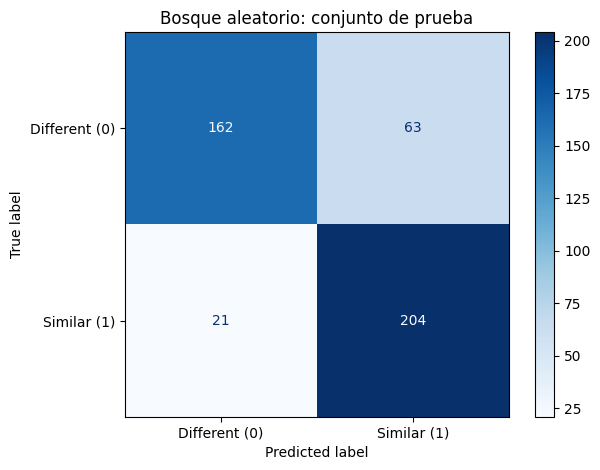

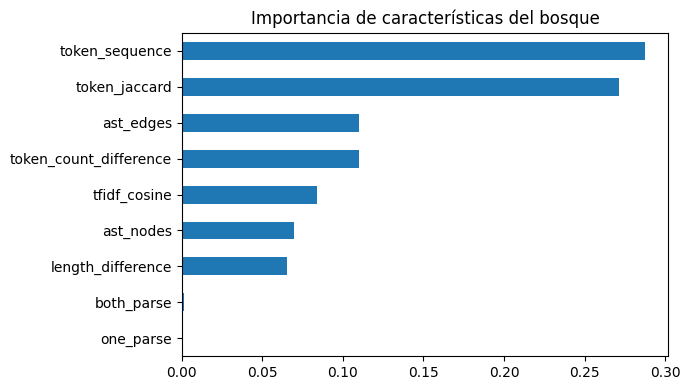

In [6]:
baseline_scores=X['test'].tfidf_cosine.to_numpy()
forest_scores=model.predict_proba(X['test'])[:,1]
rows=[]
for name,scores,threshold in [('TF-IDF baseline',baseline_scores,baseline_t),
                              ('Random Forest',forest_scores,model_t)]:
    pred=(scores>=threshold).astype(int)
    rows.append({'model':name,'accuracy':accuracy_score(y['test'],pred),
                 'precision':precision_score(y['test'],pred,zero_division=0),
                 'recall':recall_score(y['test'],pred,zero_division=0),
                 'f1':f1_score(y['test'],pred,zero_division=0),
                 'roc_auc':roc_auc_score(y['test'],scores)})
results=pd.DataFrame(rows)
display(results.round(4))
print('Random Forest classification report:')
print(classification_report(y['test'],(forest_scores>=model_t).astype(int),digits=3))
ConfusionMatrixDisplay.from_predictions(y['test'],(forest_scores>=model_t).astype(int),
                                         display_labels=['Different (0)','Similar (1)'],
                                         values_format='d',cmap='Blues')
plt.title('Bosque aleatorio: conjunto de prueba')
plt.tight_layout();plt.show()
importance=pd.Series(model.feature_importances_,index=FEATURES).sort_values()
importance.plot.barh(title='Importancia de características del bosque',figsize=(7,4))
plt.tight_layout();plt.show()

## 6. Gráficos y registro de resultados para el informe

Los gráficos finales se calculan a partir de los vectores de predicción, no de valores escritos manualmente. La matriz de confusión procede de los 450 registros de prueba. La comparación F1 emplea el mismo conjunto de validación y se diferencia explícitamente de las cifras finales de prueba.

Estos archivos pueden incorporarse en los cuatro informes individuales sin modificar los resultados compartidos.

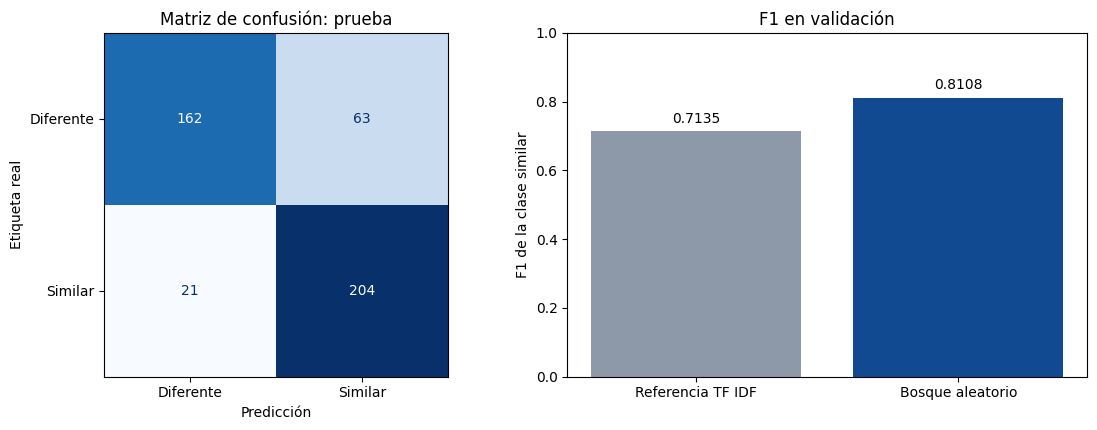

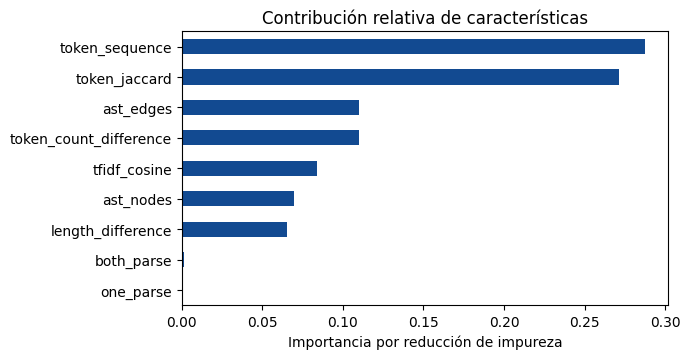

Exactitud de prueba del bosque: 0.8133
Matriz exacta de prueba:
 [[162  63]
 [ 21 204]]
Gráficos y métricas exportados a: figuras


In [7]:
from pathlib import Path
FIG_DIR = Path('/data/notebook_files/figuras') if Path('/data/notebook_files').is_dir() else Path('figuras')
FIG_DIR.mkdir(exist_ok=True, parents=True)

pred_test = (forest_scores >= model_t).astype(int)
cm = confusion_matrix(y['test'], pred_test, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Diferente', 'Similar']).plot(
    ax=axes[0], cmap='Blues', values_format='d', colorbar=False
)
axes[0].set_title('Matriz de confusión: prueba')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Etiqueta real')
labels = ['Referencia TF IDF', 'Bosque aleatorio']
values = [baseline_f1, model_f1]
axes[1].bar(labels, values, color=['#8D98A8', '#124A91'])
axes[1].set_ylim(0, 1)
axes[1].set_title('F1 en validación')
axes[1].set_ylabel('F1 de la clase similar')
for index, value in enumerate(values):
    axes[1].text(index, value + 0.025, f'{value:.4f}', ha='center')
fig.tight_layout()
fig.savefig(FIG_DIR / 'evaluacion_comparativa.png', dpi=220, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.7))
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(ax=ax, color='#124A91')
ax.set_title('Contribución relativa de características')
ax.set_xlabel('Importancia por reducción de impureza')
fig.tight_layout()
fig.savefig(FIG_DIR / 'importancia_caracteristicas.png', dpi=220, bbox_inches='tight')
plt.show()

results.to_csv(FIG_DIR / 'metricas_modelos.csv', index=False)
print('Exactitud de prueba del bosque:', round(accuracy_score(y['test'], pred_test), 4))
print('Matriz exacta de prueba:\n', cm)
print('Gráficos y métricas exportados a:', FIG_DIR)

## 7. Prueba controlada con dos fragmentos nuevos

La función de predicción recibe dos cadenas Python, calcula sus nueve características con el vectorizador previamente ajustado y entrega una predicción, un puntaje estimado y el umbral de decisión. El resultado representa afinidad con la etiqueta de PoolC; no constituye una probabilidad calibrada de plagio ni sustituye la revisión humana.

In [8]:
def predict_similarity(code_a,code_b):
    pair=pd.DataFrame({'code1':[code_a],'code2':[code_b]})
    features=make_features(pair)
    prob=float(model.predict_proba(features)[0,1])
    return {'predicted_similar':bool(prob>=model_t),
            'estimated_label_probability':round(prob,4),
            'decision_threshold':round(float(model_t),3),
            'features':features.iloc[0].round(3).to_dict()}

code_a="""def square(x):
    return x * x"""
code_b="""def calculate(n):
    return n ** 2"""
predict_similarity(code_a,code_b)

{'predicted_similar': True,
 'estimated_label_probability': 0.9421,
 'decision_threshold': 0.36,
 'features': {'token_sequence': 0.8,
  'token_jaccard': 0.667,
  'tfidf_cosine': 0.879,
  'ast_nodes': 0.816,
  'ast_edges': 0.802,
  'length_difference': 0.114,
  'token_count_difference': 0.0,
  'both_parse': 1.0,
  'one_parse': 0.0}}

## 8. Discusión metodológica y viabilidad preliminar

**Hallazgo:** el bosque aleatorio integra señales léxicas y estructurales y supera el modelo de referencia en el conjunto de prueba estudiado. La robustez se encuentra limitada por el origen de las etiquetas, por el tamaño del subconjunto y por las diferencias entre programas de competición y trabajos académicos reales.

**Riesgos:** las implementaciones independientes de un mismo problema pueden ser similares sin existir copia. A la inversa, modificaciones estructurales y semánticas profundas pueden provocar falsos negativos. La clase positiva del conjunto no identifica autores ni demuestra intención. Para uso comercial se requiere una evaluación externa, revisión de derechos del dataset, políticas de retención de código y supervisión humana de cualquier señalamiento.

**Reproducibilidad:** se proporcionan el muestreo, las características, la semilla, los hiperparámetros, las métricas y los gráficos exactos. Para evaluar escalabilidad con muchos envíos sería necesario un mecanismo de recuperación de candidatos antes de ejecutar las comparaciones por pares.

### Referencias esenciales

[1] PoolC, *1-fold-clone-detection-600k-5fold*, Hugging Face, https://huggingface.co/datasets/PoolC/1-fold-clone-detection-600k-5fold  
[2] Python Software Foundation, *ast: Abstract Syntax Trees*, https://docs.python.org/3/library/ast.html  
[3] scikit-learn, *RandomForestClassifier*, https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html  
[4] scikit-learn, *Feature extraction*, https://scikit-learn.org/stable/modules/feature_extraction.html